# Training models: optimisation, learning, and generalisation

What does "fit" actually mean?

A model is a set of parameters (or weights) you can turn. Training is the search for good values. Part 1
covers how that search works. Part 2 covers why a model that wins the search can still be
useless.

There are seven short exercises marked **Your turn**. Do each one when you reach it.

---

In [9]:
# Setup and imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import cm
from mpl_toolkits.mplot3d import Axes3D

# Set random seed for reproducibility
np.random.seed(42)

# Plotting style
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = [10, 6]
plt.rcParams['font.size'] = 12

# Suppress warnings
import warnings
warnings.filterwarnings('ignore')


---

# Session 6.1: Optimisation and learning

## 1.1 What does it mean to "train" a model?

> **Training** means finding the parameter values that make the model's predictions as close
> as possible to the data.

Linear regression makes this concrete.

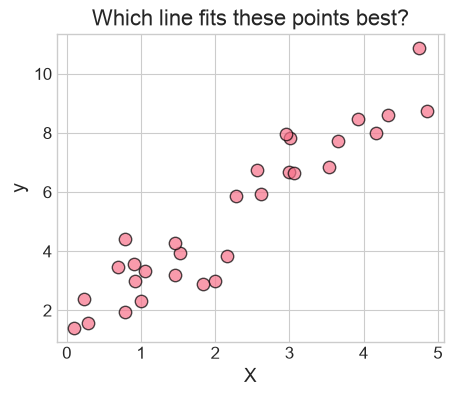

We have 30 data points.
True relationship: y = 2x + 1 + noise


In [11]:
# Generate simple linear data
np.random.seed(42)
n_points = 30

# True relationship: y = 2x + 1 + noise
TRUE_SLOPE = 2
TRUE_INTERCEPT = 1

X_simple = np.random.uniform(0, 5, n_points)
y_simple = TRUE_SLOPE * X_simple + TRUE_INTERCEPT + np.random.normal(0, 1, n_points)

X_simple[0] = 2
y_simple[0] = 3

# Visualise the data
plt.figure(figsize=(5, 4))
plt.scatter(X_simple, y_simple, s=80, alpha=0.7, edgecolors='black', linewidth=1)
plt.xlabel('X', fontsize=14)
plt.ylabel('y', fontsize=14)
plt.title('Which line fits these points best?', fontsize=16)
plt.show()

print(f"We have {n_points} data points.")
print(f"True relationship: y = {TRUE_SLOPE}x + {TRUE_INTERCEPT} + noise")


We want a line $\hat{y} = mx + b$ that fits well. But "fits well" has to be **measured**
before it can be searched for. That measurement is the **loss function**.

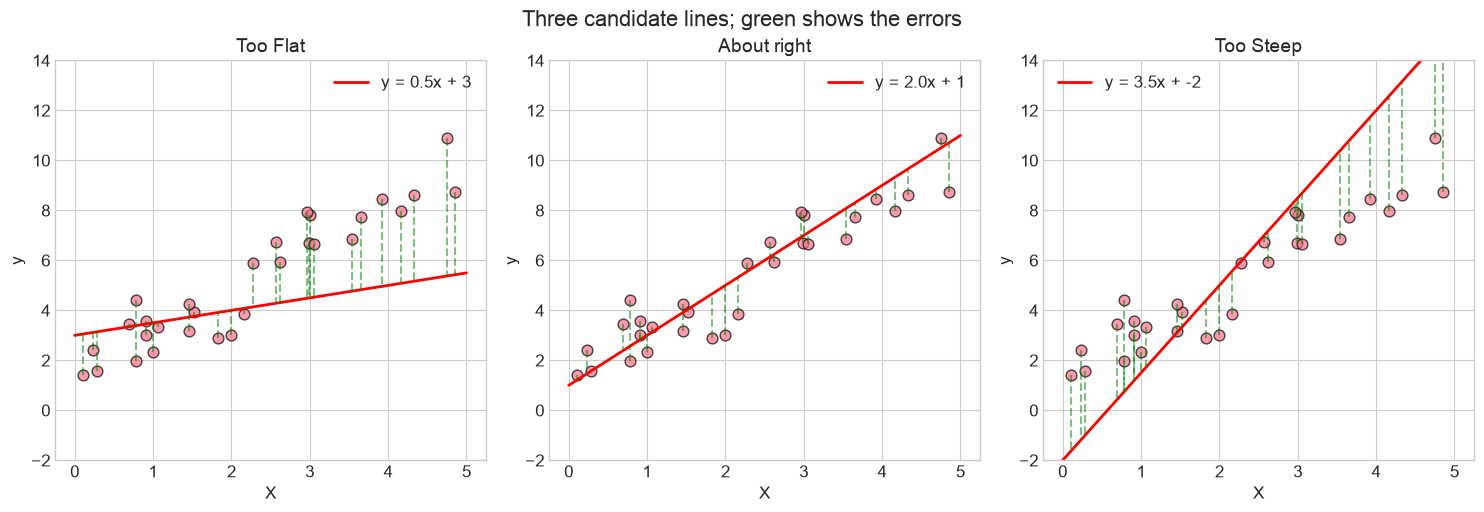

In [12]:
# Three candidate lines, scored by eye
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Three different guesses for the line
guesses = [
    (0.5, 3, 'Too Flat'),
    (2.0, 1, 'About right'),
    (3.5, -2, 'Too Steep')
]

x_line = np.linspace(0, 5, 100)

for ax, (slope, intercept, title) in zip(axes, guesses):
    ax.scatter(X_simple, y_simple, s=60, alpha=0.7, edgecolors='black', linewidth=1)
    y_pred = slope * x_line + intercept
    ax.plot(x_line, y_pred, 'r-', linewidth=2, label=f'y = {slope}x + {intercept}')
    
    # Draw residuals for a few points
    for i in range(0, n_points):
        y_hat = slope * X_simple[i] + intercept
        ax.plot([X_simple[i], X_simple[i]], [y_simple[i], y_hat], 'g--', alpha=0.5)
    
    ax.set_xlabel('X')
    ax.set_ylabel('y')
    ax.set_title(title, fontsize=14)
    ax.legend()
    ax.set_ylim(-2, 14)

plt.tight_layout()
plt.suptitle('Three candidate lines; green shows the errors', fontsize=16, y=1.02)
plt.show()


The green dashed lines are the errors, or **residuals**.

---

## 1.2 Loss functions

A **loss function** turns "how wrong is this model" into one number. Training minimises it.

For regression the usual choice is **mean squared error**:

$$\mathcal{L}_{MSE} = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$

**Why squared?** Positive and negative errors stop cancelling out, large errors are punished
disproportionately, and the result is smooth and differentiable, which matters in §1.3.

In [13]:
def mse_loss(y_true, y_pred):
    """Calculate Mean Squared Error"""
    return np.mean((y_true - y_pred) ** 2)

def predict(X, slope, intercept):
    """Simple linear prediction"""
    return slope * X + intercept

# Calculate loss for each of our guesses
print("Loss (MSE) for different line guesses:")
print("=" * 45)
for slope, intercept, title in guesses:
    y_pred = predict(X_simple, slope, intercept)
    loss = mse_loss(y_simple, y_pred)
    print(f"{title:15} (m={slope}, b={intercept}): MSE = {loss:.2f}")

print()
print("Lower MSE means a closer fit.")


Loss (MSE) for different line guesses:
Too Flat        (m=0.5, b=3): MSE = 4.80
About right     (m=2.0, b=1): MSE = 0.94
Too Steep       (m=3.5, b=-2): MSE = 7.09

Lower MSE means a closer fit.


> ### Your turn 1: mean absolute error
>
> Squaring is a choice. Mean absolute error does not square:
> $\mathcal{L}_{MAE} = \frac{1}{n}\sum|y_i - \hat{y}_i|$
>
> 1. Write `mae_loss`.
> 2. Score the three guesses with both losses. Do they agree on the winner?
> 3. Move one house a long way from its price and score again. Which loss notices more?

In [16]:
def mae_loss(y_true, y_pred):
    """Mean Absolute Error."""
    return np.mean(np.abs(y_true - y_pred))

# 2. both losses on the three guesses
for slope, intercept, title in guesses:
    y_pred = predict(X_simple, slope, intercept)
    print(f"{title}")
    print(mae_loss(y_simple, y_pred), mse_loss(y_simple, y_pred))
    ...

# 3. one point moved a long way
y_outlier = y_simple.copy()
y_outlier[0] += 30
y_pred = predict(X_simple, 2.0, 1)   # the middle line
# TODO: compare both losses on y_simple and on y_outlier

Too Flat
1.7521469198244064 4.802783875111018
About right
0.7879869878273751 0.9435892362393105
Too Steep
2.2102481251282047 7.093838388529345


<details>
<summary>What you should see</summary>

Both losses pick the same winner on clean data. Move one point by 30 and:

| | clean | with the outlier | |
|---|---|---|---|
| MSE | 0.85 | 28.55 | ×33 |
| MAE | 0.76 | 1.68 | ×2.2 |

Squaring means one unusual house pulls the fitted line more than thirty ordinary ones.
Sometimes that is what you want. MAE and Huber loss are the alternatives when it is not.
</details>

### The loss landscape

We guessed three slopes and three intercepts out of infinitely many. How do we choose?

Brute force, scoring every combination on a grid, is impractical for real models but useful
for seeing the problem. Every $(m, b)$ pair has a loss, so the losses form a surface: the
**loss landscape**.

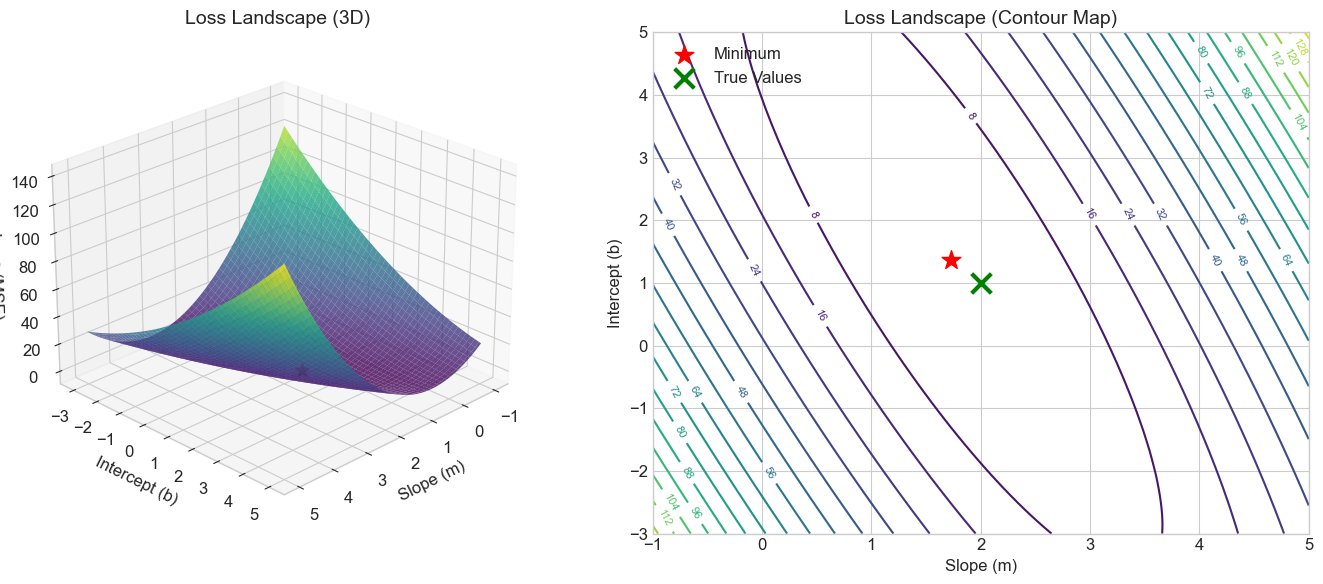

Best parameters found: slope = 1.73, intercept = 1.36
True parameters:       slope = 2.00, intercept = 1.00


In [146]:
# Create a grid of slope and intercept values
slopes = np.linspace(-1, 5, 100)
intercepts = np.linspace(-3, 5, 100)
SLOPES, INTERCEPTS = np.meshgrid(slopes, intercepts)

# Calculate loss for each combination
LOSS = np.zeros_like(SLOPES) # creates a grid of zeros with the same shape as SLOPES and INTERCEPTS
for i in range(len(slopes)):
    for j in range(len(intercepts)):
        y_pred = predict(X_simple, SLOPES[j, i], INTERCEPTS[j, i])
        LOSS[j, i] = mse_loss(y_simple, y_pred)

# Create 3D surface plot
fig = plt.figure(figsize=(14, 6))

# 3D view
ax1 = fig.add_subplot(1, 2, 1, projection='3d')
surf = ax1.plot_surface(SLOPES, INTERCEPTS, LOSS, cmap='viridis', alpha=0.8)
ax1.set_xlabel('Slope (m)', fontsize=12)
ax1.set_ylabel('Intercept (b)', fontsize=12)
ax1.set_zlabel('Loss (MSE)', fontsize=12)
ax1.set_title('Loss Landscape (3D)', fontsize=14)
ax1.view_init(elev=25, azim=45)

# Mark the minimum
min_idx = np.unravel_index(np.argmin(LOSS), LOSS.shape)
best_slope = SLOPES[min_idx]
best_intercept = INTERCEPTS[min_idx]
best_loss = LOSS[min_idx]
ax1.scatter([best_slope], [best_intercept], [best_loss], color='red', s=100, marker='*', label='Minimum')

# 2D contour view
ax2 = fig.add_subplot(1, 2, 2)
contour = ax2.contour(SLOPES, INTERCEPTS, LOSS, levels=20, cmap='viridis')
ax2.clabel(contour, inline=True, fontsize=8)
ax2.scatter([best_slope], [best_intercept], color='red', s=200, marker='*', label='Minimum', zorder=5)
ax2.scatter([TRUE_SLOPE], [TRUE_INTERCEPT], color='green', s=200, marker='x', linewidths=3, label='True Values', zorder=5)
ax2.set_xlabel('Slope (m)', fontsize=12)
ax2.set_ylabel('Intercept (b)', fontsize=12)
ax2.set_title('Loss Landscape (Contour Map)', fontsize=14)
ax2.legend()

plt.tight_layout()
plt.show()

print(f"Best parameters found: slope = {best_slope:.2f}, intercept = {best_intercept:.2f}")
print(f"True parameters:       slope = {TRUE_SLOPE:.2f}, intercept = {TRUE_INTERCEPT:.2f}")


Training a model means finding the lowest point in this landscape. The red star marks the
minimum loss on our grid: those are the fitted parameters.

**Test your understanding**: why is the star not exactly on the green mark, the parameters the
data was generated from?

<details>
<summary>Answer</summary>

Two reasons, and both can apply at once.

1. We sampled a finite grid of slopes and intercepts, so we may have stepped over the exact
   minimum. Increase the resolution and see whether it moves closer.
2. The loss was computed on 30 points, which is a noisy sample. The minimum for the full
   population would sit elsewhere. Increase `n_points` and see whether it shifts.
</details>

> **Classification uses different losses.** Predicting a probability rather than a number
> calls for cross-entropy, which punishes confident wrong answers hardest. You meet it in
> Week 7, with Prof. Adam Kenny.

---

## 1.3 Gradient descent

Linear regression has a closed-form solution. Almost nothing else does, and brute force gets
exponentially worse with every parameter you add. Gradient descent is what is used in practice.

Imagine standing blindfolded on that landscape:

1. feel the slope under your feet (compute the gradient)
2. step downhill (move against the gradient)
3. repeat

$$\theta_{new} = \theta_{old} - \eta \cdot \nabla \mathcal{L}(\theta)$$

where $\eta$ is the **learning rate**, the size of each step.

In [147]:
def compute_gradients(X, y, slope, intercept):
    """Compute gradients for MSE loss with respect to slope and intercept"""
    n = len(y)
    y_pred = slope * X + intercept
    error = y_pred - y
    
    grad_slope = (2/n) * np.sum(error * X)
    grad_intercept = (2/n) * np.sum(error)
    
    return grad_slope, grad_intercept

def gradient_descent(X, y, learning_rate=0.1, n_iterations=50, init_slope=0, init_intercept=0):
    """Run gradient descent and record the path"""
    slope = init_slope
    intercept = init_intercept
    
    history = {
        'slopes': [slope],
        'intercepts': [intercept],
        'losses': [mse_loss(y, predict(X, slope, intercept))]
    }
    
    for i in range(n_iterations):
        grad_slope, grad_intercept = compute_gradients(X, y, slope, intercept)
        
        slope = slope - learning_rate * grad_slope
        intercept = intercept - learning_rate * grad_intercept
        
        history['slopes'].append(slope)
        history['intercepts'].append(intercept)
        history['losses'].append(mse_loss(y, predict(X, slope, intercept)))
    
    return slope, intercept, history

# Run gradient descent
final_slope, final_intercept, history = gradient_descent(
    X_simple, y_simple, 
    learning_rate=0.05, 
    n_iterations=100,
    init_slope=-0.5,
    init_intercept=4
)

print(f"Starting point:  slope = -0.50, intercept = 4.00")
print(f"Final result:    slope = {final_slope:.2f}, intercept = {final_intercept:.2f}")
print(f"True values:     slope = {TRUE_SLOPE:.2f}, intercept = {TRUE_INTERCEPT:.2f}")


Starting point:  slope = -0.50, intercept = 4.00
Final result:    slope = 1.65, intercept = 1.62
True values:     slope = 2.00, intercept = 1.00


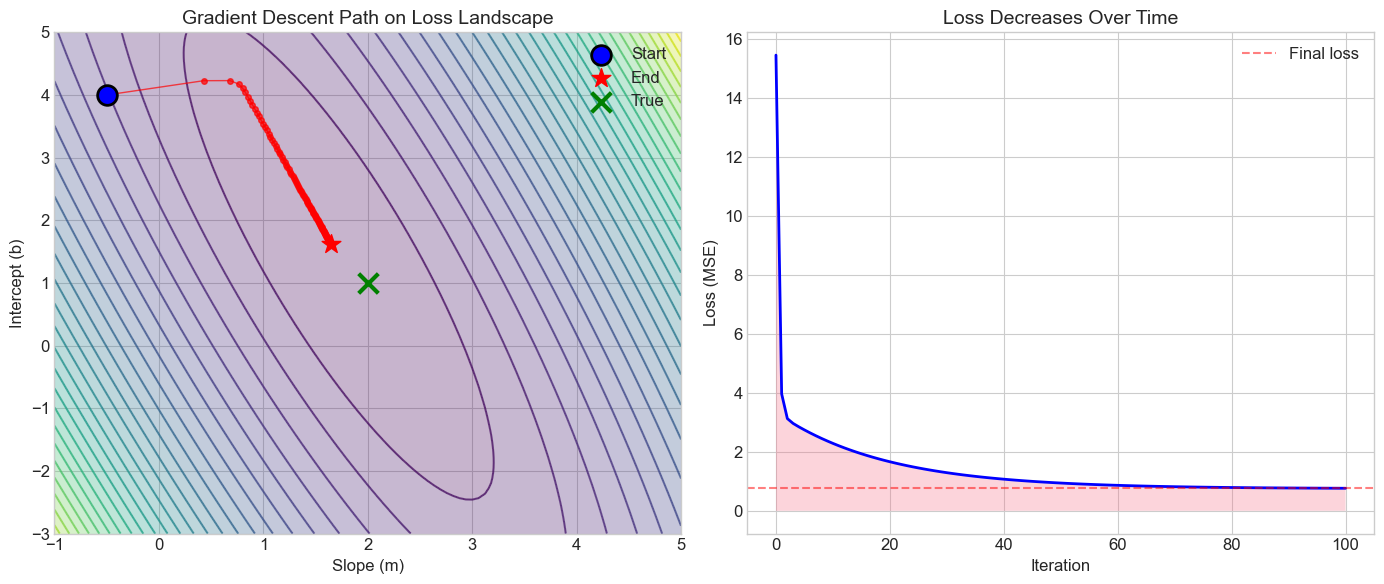

In [148]:
# Visualise gradient descent path on the loss landscape
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Left: Path on contour plot
contour = axes[0].contour(SLOPES, INTERCEPTS, LOSS, levels=30, cmap='viridis', alpha=0.7)
axes[0].contourf(SLOPES, INTERCEPTS, LOSS, levels=30, cmap='viridis', alpha=0.3)

# Plot the path
path_slopes = history['slopes']
path_intercepts = history['intercepts']
axes[0].plot(path_slopes, path_intercepts, 'ro-', markersize=4, linewidth=1, alpha=0.7)
axes[0].scatter([path_slopes[0]], [path_intercepts[0]], color='blue', s=200, marker='o', 
                label='Start', zorder=5, edgecolors='black', linewidth=2)
axes[0].scatter([path_slopes[-1]], [path_intercepts[-1]], color='red', s=200, marker='*', 
                label='End', zorder=5)
axes[0].scatter([TRUE_SLOPE], [TRUE_INTERCEPT], color='green', s=200, marker='x', 
                linewidths=3, label='True', zorder=5)

axes[0].set_xlabel('Slope (m)', fontsize=12)
axes[0].set_ylabel('Intercept (b)', fontsize=12)
axes[0].set_title('Gradient Descent Path on Loss Landscape', fontsize=14)
axes[0].legend(loc='upper right')
axes[0].set_xlim(-1, 5)
axes[0].set_ylim(-3, 5)

# Right: Loss over iterations
axes[1].plot(history['losses'], 'b-', linewidth=2)
axes[1].fill_between(range(len(history['losses'])), history['losses'], alpha=0.3)
axes[1].set_xlabel('Iteration', fontsize=12)
axes[1].set_ylabel('Loss (MSE)', fontsize=12)
axes[1].set_title('Loss Decreases Over Time', fontsize=14)
axes[1].axhline(y=history['losses'][-1], color='r', linestyle='--', alpha=0.5, label='Final loss')
axes[1].legend()

plt.tight_layout()
plt.show()


> ### Your turn 2: does the starting point matter?
>
> Run `gradient_descent` again from `init_slope=5`, `init_intercept=-3`. Print the final
> slope and intercept. Same answer or not?

In [149]:
slope_b, intercept_b, history_b = gradient_descent(
    X_simple, y_simple,
    learning_rate=0.05, n_iterations=100,
    # TODO: start somewhere else
)

print(f"from (-0.5, 4.0): slope = {final_slope:.2f}, intercept = {final_intercept:.2f}")
# TODO: print the result from the new starting point

from (-0.5, 4.0): slope = 1.65, intercept = 1.62


<details>
<summary>Answer</summary>

The same place, to two decimals. This loss landscape is **convex**: one bowl, one bottom, so
every starting point ends at the same minimum and only the path differs. In §1.3 we will see when that is not the case.
</details>

### The learning rate

- **too small**: converges, slowly
- **too large**: overshoots, and may never settle

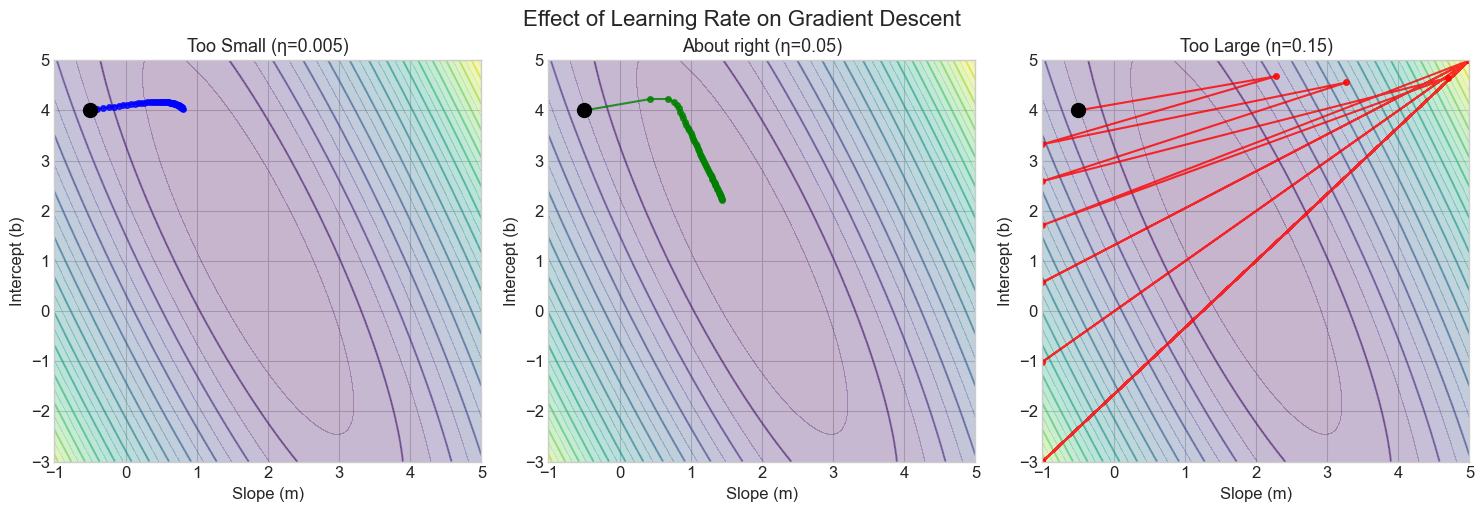

In [150]:
# Compare different learning rates
learning_rates = [0.005, 0.05, 0.15]
colors = ['blue', 'green', 'red']
labels = ['Too Small (η=0.005)', 'About right (η=0.05)', 'Too Large (η=0.15)']

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, lr, color, label in zip(axes, learning_rates, colors, labels):
    # Run gradient descent with this learning rate
    try:
        _, _, hist = gradient_descent(
            X_simple, y_simple,
            learning_rate=lr,
            n_iterations=50,
            init_slope=-0.5,
            init_intercept=4
        )
        
        # Plot path on contour
        ax.contourf(SLOPES, INTERCEPTS, LOSS, levels=30, cmap='viridis', alpha=0.3)
        ax.contour(SLOPES, INTERCEPTS, LOSS, levels=15, cmap='viridis', alpha=0.5)
        
        # Clip path to visible range for plotting
        path_s = np.clip(hist['slopes'], -1, 5)
        path_i = np.clip(hist['intercepts'], -3, 5)
        
        ax.plot(path_s, path_i, 'o-', color=color, markersize=4, linewidth=1.5, alpha=0.8)
        ax.scatter([hist['slopes'][0]], [hist['intercepts'][0]], color='black', s=100, 
                   marker='o', zorder=5, label='Start')
        
        ax.set_xlabel('Slope (m)')
        ax.set_ylabel('Intercept (b)')
        ax.set_title(label, fontsize=13)
        ax.set_xlim(-1, 5)
        ax.set_ylim(-3, 5)
        
    except:
        ax.set_title(f'{label}\n(diverged)', fontsize=13)

plt.tight_layout()
plt.suptitle('Effect of Learning Rate on Gradient Descent', fontsize=16, y=1.02)
plt.show()


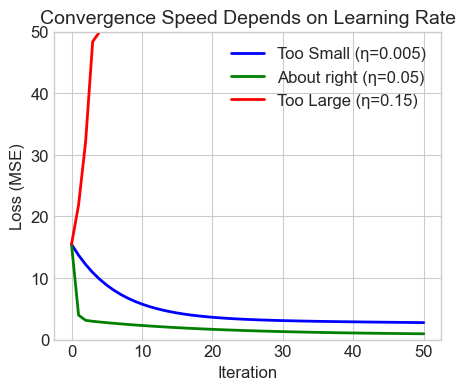

In [151]:
# Show loss curves for different learning rates
fig, ax = plt.subplots(figsize=(5, 4))

for lr, color, label in zip(learning_rates, colors, labels):
    _, _, hist = gradient_descent(
        X_simple, y_simple,
        learning_rate=lr,
        n_iterations=50,
        init_slope=-0.5,
        init_intercept=4
    )
    # Clip for visualisation
    losses = np.clip(hist['losses'], 0, 50)
    ax.plot(losses, color=color, linewidth=2, label=label)

ax.set_xlabel('Iteration', fontsize=12)
ax.set_ylabel('Loss (MSE)', fontsize=12)
ax.set_title('Convergence Speed Depends on Learning Rate', fontsize=14)
ax.legend()
ax.set_ylim(0, 50)
plt.show()


> ### Your turn 3: where does it break?
>
> 1. Run gradient descent at each rate below.
> 2. Print the final loss for each. Which converged, which crawled, which diverged?
> 3. Narrow down the largest rate that still converges.

In [152]:
learning_rates_to_try = [0.001, 0.01, 0.1, 0.5]

for lr in learning_rates_to_try:
    # TODO: run gradient_descent with this learning rate
    # TODO: print the final loss (watch out for nan / inf)
    pass

### Not every landscape is a bowl

Linear regression's landscape is convex, which is why Your turn 2 came out the way it did.
Neural networks are not convex: they have many **local minima**, and the starting point
changes where you end up. This is why initialisation matters, and why momentum, random
restarts and learning-rate schedules exist. All of that is beyond this module; the term to
search for is "non-convex optimisation".

---

## 1.4 Why optimisation alone is not enough

Everything so far minimised loss on the **training data**. But a model that fits the training
data perfectly can be useless on anything else.

- **Optimisation**: minimise loss on data you have
- **Generalisation**: perform well on data you do not

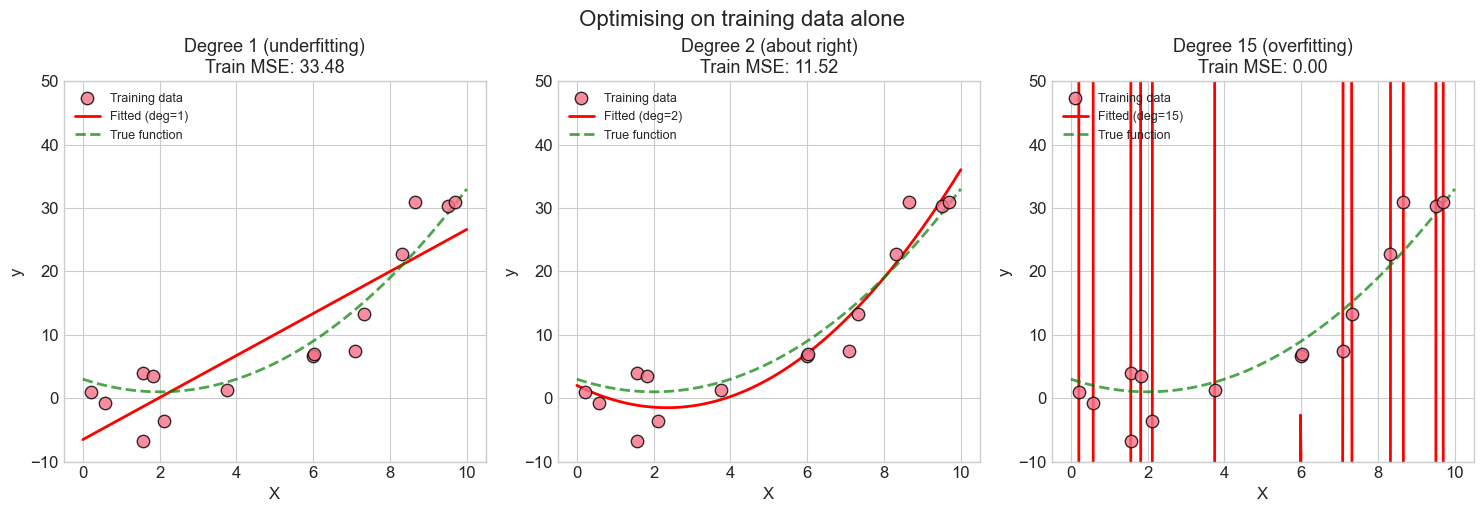

In [153]:
# Generate data from a simple quadratic function
np.random.seed(42)
n_train = 15

X_train = np.sort(np.random.uniform(0, 10, n_train))
y_true_func = lambda x: 0.5 * x**2 - 2*x + 3  # True function
y_train = y_true_func(X_train) + np.random.normal(0, 3, n_train)

# Generate test data
X_test = np.linspace(0, 10, 100)
y_test = y_true_func(X_test) + np.random.normal(0, 3, 100)

# Fit polynomials of different degrees
from numpy.polynomial import polynomial as P

degrees = [1, 2, 15]  # Underfitting, just right, overfitting
titles = ['Degree 1 (underfitting)', 'Degree 2 (about right)', 'Degree 15 (overfitting)']

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

X_plot = np.linspace(0, 10, 200)

for ax, degree, title in zip(axes, degrees, titles):
    # Fit polynomial
    coeffs = np.polyfit(X_train, y_train, degree)
    y_fit = np.polyval(coeffs, X_plot)
    y_train_pred = np.polyval(coeffs, X_train)
    
    # Calculate errors
    train_mse = mse_loss(y_train, y_train_pred)
    
    # Plot
    ax.scatter(X_train, y_train, s=80, alpha=0.8, edgecolors='black', linewidth=1, 
               label='Training data', zorder=5)
    ax.plot(X_plot, y_fit, 'r-', linewidth=2, label=f'Fitted (deg={degree})')
    ax.plot(X_plot, y_true_func(X_plot), 'g--', linewidth=2, alpha=0.7, label='True function')
    
    ax.set_xlabel('X')
    ax.set_ylabel('y')
    ax.set_title(f'{title}\nTrain MSE: {train_mse:.2f}', fontsize=13)
    ax.legend(loc='upper left', fontsize=9)
    ax.set_ylim(-10, 50)

plt.tight_layout()
plt.suptitle('Optimising on training data alone', fontsize=16, y=1.02)
plt.show()


# Session 6.2: Generalisation and overfitting

## 2.1 Overfitting and underfitting

There are two ways a model can fail:

| Problem | Description | Symptom |
|---------|-------------|---------|
| **Underfitting** | too simple to capture the pattern | high error on both training and test data |
| **Overfitting** | complex enough to memorise the noise | low training error, high test error |

What you want is in between: complex enough to capture the pattern, not so complex that it
fits the noise as well.

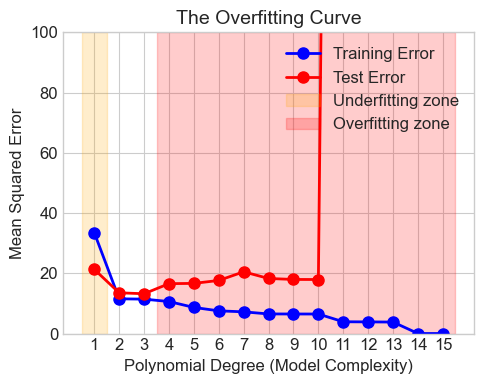

Training error keeps decreasing; test error has a minimum.
Best test performance at degree: 3


In [154]:
# Systematic comparison across polynomial degrees
max_degree = 15
train_errors = []
test_errors = []

for degree in range(1, max_degree + 1):
    coeffs = np.polyfit(X_train, y_train, degree)
    
    y_train_pred = np.polyval(coeffs, X_train)
    y_test_pred = np.polyval(coeffs, X_test)
    
    train_errors.append(mse_loss(y_train, y_train_pred))
    test_errors.append(mse_loss(y_test, y_test_pred))

# Plot
fig, ax = plt.subplots(figsize=(5, 4))

degrees_range = range(1, max_degree + 1)
ax.plot(degrees_range, train_errors, 'b-o', linewidth=2, markersize=8, label='Training Error')
ax.plot(degrees_range, test_errors, 'r-o', linewidth=2, markersize=8, label='Test Error')

# Mark regions
ax.axvspan(0.5, 1.5, alpha=0.2, color='orange', label='Underfitting zone')
ax.axvspan(3.5, 15.5, alpha=0.2, color='red', label='Overfitting zone')

ax.set_xlabel('Polynomial Degree (Model Complexity)', fontsize=12)
ax.set_ylabel('Mean Squared Error', fontsize=12)
ax.set_title('The Overfitting Curve', fontsize=14)
ax.legend(loc='upper right')
ax.set_xticks(degrees_range)
ax.set_ylim(0, 100)

plt.tight_layout()
plt.show()

print("Training error keeps decreasing; test error has a minimum.")
print(f"Best test performance at degree: {np.argmin(test_errors) + 1}")


Three things to read off that plot:

1. **Training error always falls** as complexity rises.
2. **Test error falls, bottoms out, then climbs.** That is the U-shape.
3. **The gap between the two curves is overfitting.**

> ### Your turn 4: your own overfitting curve
>
> Same experiment, different underlying function.
>
> 1. Generate 30 points from $y = \sin(x) + \text{noise}$ over $[0, 2\pi]$.
> 2. Split into train and test.
> 3. Fit polynomials of degree 1, 3, 5, 10 and 20.
> 4. Plot training error and test error against degree. Which degree underfits? Which overfits?
> 5. Re-run with 300 points instead of 30. What happens to the overfitting zone?

In [155]:
np.random.seed(42)

X_sine = np.random.uniform(0, 2 * np.pi, 30)
y_sine = ...   # TODO: np.sin(X_sine) + noise

# TODO: split into train and test
# TODO: fit each degree, record train and test MSE
# TODO: plot both against degree

---

## 2.2 The bias-variance trade-off

Overfitting has a decomposition. A model's expected error is three things:

$$\text{Expected Error} = \text{Bias}^2 + \text{Variance} + \text{Irreducible Noise}$$

| Component | Meaning | Caused by |
|-----------|---------|-----------|
| **Bias** | error from wrong assumptions | model too simple |
| **Variance** | error from sensitivity to the training data | model too complex |
| **Noise** | randomness in the data itself | cannot be reduced |

To see variance, train the same model on twenty different samples and look at the spread.

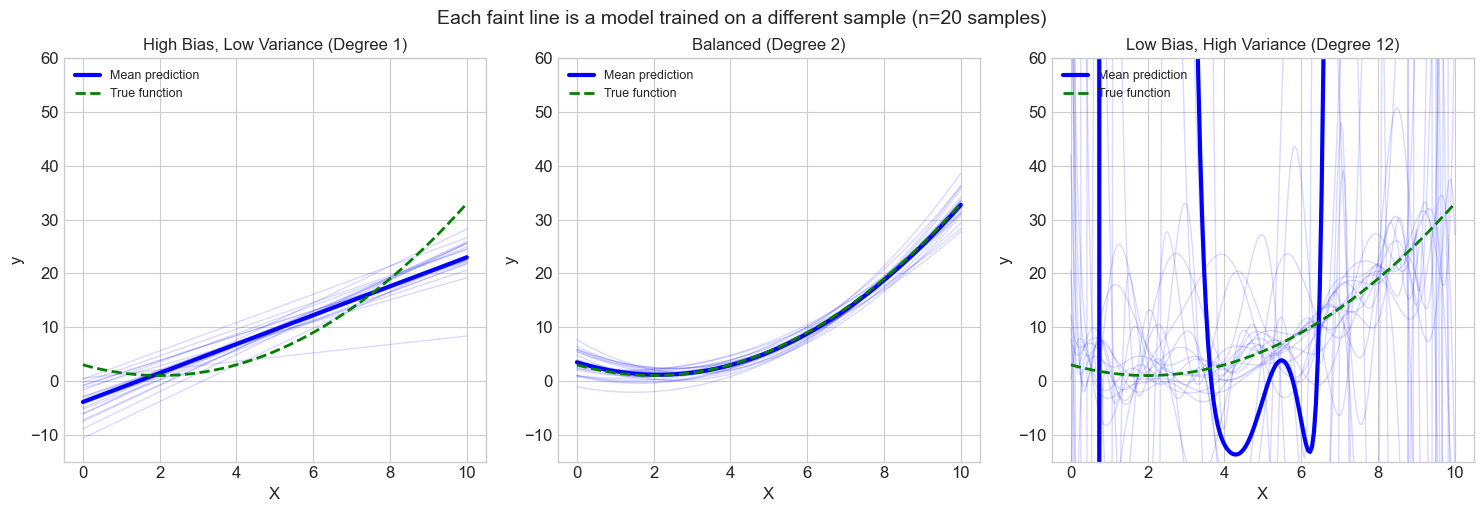

In [156]:
# Generate multiple training sets and fit models
n_datasets = 20
n_samples = 15

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
X_plot = np.linspace(0, 10, 200)

for ax, degree, title in zip(axes, [1, 2, 12], ['High Bias, Low Variance (Degree 1)', 
                                                  'Balanced (Degree 2)', 
                                                  'Low Bias, High Variance (Degree 12)']):
    all_predictions = []
    
    for seed in range(n_datasets):
        np.random.seed(seed)
        X_sample = np.sort(np.random.uniform(0, 10, n_samples))
        y_sample = y_true_func(X_sample) + np.random.normal(0, 3, n_samples)
        
        coeffs = np.polyfit(X_sample, y_sample, degree)
        y_pred = np.polyval(coeffs, X_plot)
        all_predictions.append(y_pred)
        
        ax.plot(X_plot, y_pred, 'b-', alpha=0.15, linewidth=1)
    
    # Plot mean prediction
    mean_pred = np.mean(all_predictions, axis=0)
    ax.plot(X_plot, mean_pred, 'b-', linewidth=3, label='Mean prediction')
    
    # Plot true function
    ax.plot(X_plot, y_true_func(X_plot), 'g--', linewidth=2, label='True function')
    
    ax.set_xlabel('X')
    ax.set_ylabel('y')
    ax.set_title(title, fontsize=12)
    ax.legend(loc='upper left', fontsize=9)
    ax.set_ylim(-15, 60)

plt.tight_layout()
plt.suptitle(f'Each faint line is a model trained on a different sample (n={n_datasets} samples)', 
             fontsize=14, y=1.02)
plt.show()


- **Degree 1**: every fit looks the same (low variance) and every fit is wrong in the same
  way (high bias). It cannot bend.
- **Degree 12**: the fits disagree with each other. Change the sample, change the model.
- **Degree 2**: clustered around the true function, with a reasonable spread.

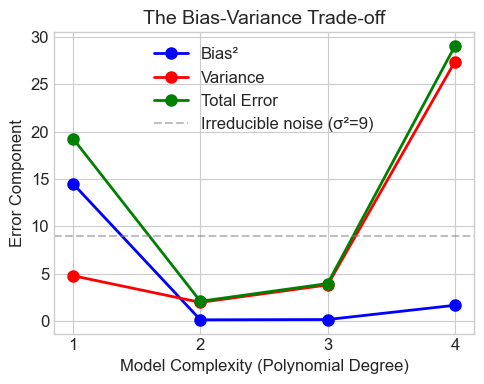

In [157]:
# Quantify bias and variance across model complexity
degrees_to_test = range(1, 5)
n_datasets = 50

bias_squared_list = []
variance_list = []
total_error_list = []

for degree in degrees_to_test:
    all_predictions = []
    
    for seed in range(n_datasets):
        np.random.seed(seed)
        X_sample = np.sort(np.random.uniform(0, 10, n_samples))
        y_sample = y_true_func(X_sample) + np.random.normal(0, 3, n_samples)
        
        coeffs = np.polyfit(X_sample, y_sample, min(degree, len(X_sample)-1))
        y_pred = np.polyval(coeffs, X_plot)
        all_predictions.append(y_pred)
    
    all_predictions = np.array(all_predictions)
    mean_prediction = np.mean(all_predictions, axis=0)
    true_values = y_true_func(X_plot)
    
    # Bias squared: (mean prediction - true)^2
    bias_sq = np.mean((mean_prediction - true_values) ** 2)
    
    # Variance: average variance of predictions
    variance = np.mean(np.var(all_predictions, axis=0))
    
    bias_squared_list.append(bias_sq)
    variance_list.append(variance)
    total_error_list.append(bias_sq + variance)

# Plot
fig, ax = plt.subplots(figsize=(5, 4))

ax.plot(degrees_to_test, bias_squared_list, 'b-o', linewidth=2, markersize=8, label='Bias²')
ax.plot(degrees_to_test, variance_list, 'r-o', linewidth=2, markersize=8, label='Variance')
ax.plot(degrees_to_test, total_error_list, 'g-o', linewidth=2, markersize=8, label='Total Error')
# ax.set_yscale('log')
ax.axhline(y=9, color='gray', linestyle='--', alpha=0.5, label='Irreducible noise (σ²=9)')

ax.set_xlabel('Model Complexity (Polynomial Degree)', fontsize=12)
ax.set_ylabel('Error Component', fontsize=12)
ax.set_title('The Bias-Variance Trade-off', fontsize=14)
ax.legend()
ax.set_xticks(degrees_to_test)

plt.tight_layout()
plt.show()


As complexity rises, bias falls and variance rises. Total error has a minimum somewhere in
between, and finding it is much of what applied machine learning consists of.

This is what **capacity** means: the range of functions a model can represent. Too little and
it cannot fit the pattern; too much and it fits the noise as well. A large dataset supports
high capacity; a small one does not.

> Von Neumann: *"With four parameters I can fit an elephant, and with five I can make him
> wiggle his trunk."* 3Blue1Brown
> [draws the elephant](https://www.youtube.com/watch?v=r6sGWTCMz2k).

> ### Your turn 5: bias and variance on a different function
>
> Repeat the plot above for a function that oscillates and decays:
> $f(x) = e^{-x/5} \sin(x)$
>
> Fit degrees 1, 3 and 7 to twenty samples each. Which degree balances bias against variance
> here, and is it the same answer as for the quadratic?

In [158]:
def new_true_func(x):
    return np.exp(-x / 5) * np.sin(x)

# TODO: for each degree, fit 20 samples and plot every fit faintly
# TODO: overlay the mean fit and the true function

---

## 2.3 Train-test split

To detect overfitting, hold data back. Train on one part, score on the part the model has
never seen.

1. split, typically 80 / 20
2. fit on the training set only
3. score on the test set
4. that score is your estimate of performance on new data

In [159]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error

# Generate a larger dataset
np.random.seed(42)
n_total = 100
X_full = np.random.uniform(0, 10, n_total).reshape(-1, 1)
y_full = y_true_func(X_full.flatten()) + np.random.normal(0, 3, n_total)

# Train-test split
X_train_split, X_test_split, y_train_split, y_test_split = train_test_split(
    X_full, y_full, test_size=0.2, random_state=42
)

print(f"Total samples: {n_total}")
print(f"Training samples: {len(X_train_split)} ({len(X_train_split)/n_total*100:.0f}%)")
print(f"Test samples: {len(X_test_split)} ({len(X_test_split)/n_total*100:.0f}%)")


Total samples: 100
Training samples: 80 (80%)
Test samples: 20 (20%)


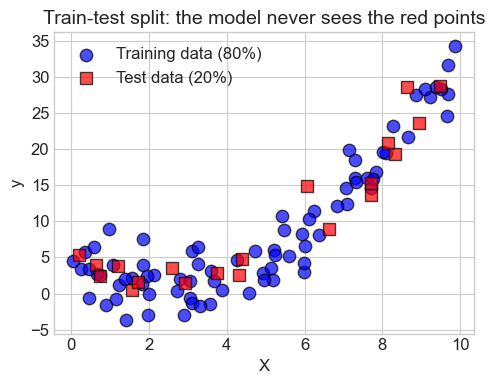

In [160]:
# Visualise the split
fig, ax = plt.subplots(figsize=(5, 4))

ax.scatter(X_train_split, y_train_split, s=80, alpha=0.7, label='Training data (80%)', 
           edgecolors='black', linewidth=1, c='blue')
ax.scatter(X_test_split, y_test_split, s=80, alpha=0.7, label='Test data (20%)', 
           edgecolors='black', linewidth=1, c='red', marker='s')

ax.set_xlabel('X', fontsize=12)
ax.set_ylabel('y', fontsize=12)
ax.set_title('Train-test split: the model never sees the red points', fontsize=14)
ax.legend()

plt.tight_layout()
plt.show()


In [161]:
# Compare models using train-test split
degrees_to_try = [1, 2, 5, 10, 15]

results = []
for degree in degrees_to_try:
    # Create and train model
    model = make_pipeline(
        PolynomialFeatures(degree, include_bias=False),
        LinearRegression()
    )
    model.fit(X_train_split, y_train_split)
    
    # Evaluate on both sets
    train_pred = model.predict(X_train_split)
    test_pred = model.predict(X_test_split)
    
    train_mse = mean_squared_error(y_train_split, train_pred)
    test_mse = mean_squared_error(y_test_split, test_pred)
    
    results.append({
        'Degree': degree,
        'Train MSE': train_mse,
        'Test MSE': test_mse,
        'Gap': test_mse - train_mse
    })

results_df = pd.DataFrame(results)
print("Model Comparison Using Train-Test Split")
print("=" * 55)
print(results_df.to_string(index=False))
print()
print("A large gap between train and test error indicates overfitting.")


Model Comparison Using Train-Test Split
 Degree  Train MSE  Test MSE       Gap
      1  25.767890 20.603564 -5.164326
      2   7.332438  5.722565 -1.609873
      5   7.072911  6.173430 -0.899481
     10   6.933461  5.950848 -0.982613
     15   6.709132  6.815753  0.106621

A large gap between train and test error indicates overfitting.


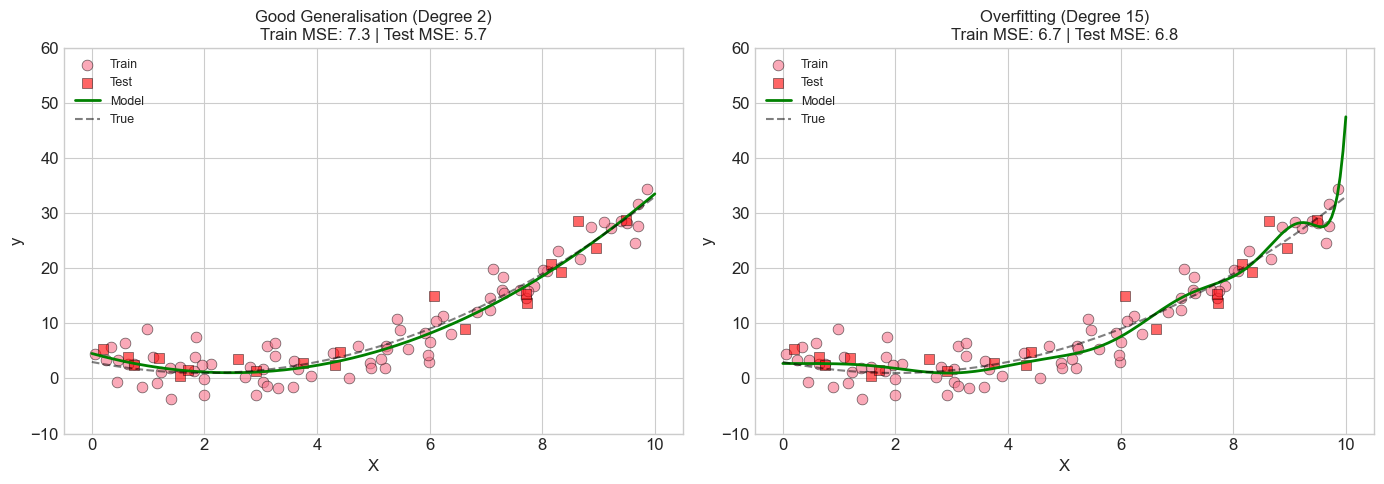

In [162]:
# Visualise the best and worst models
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

X_plot_2d = np.linspace(0, 10, 200).reshape(-1, 1)

for ax, degree, title in zip(axes, [2, 15], ['Good Generalisation (Degree 2)', 
                                               'Overfitting (Degree 15)']):
    model = make_pipeline(
        PolynomialFeatures(degree, include_bias=False),
        LinearRegression()
    )
    model.fit(X_train_split, y_train_split)
    
    y_plot = model.predict(X_plot_2d)
    
    # Calculate errors
    train_mse = mean_squared_error(y_train_split, model.predict(X_train_split))
    test_mse = mean_squared_error(y_test_split, model.predict(X_test_split))
    
    ax.scatter(X_train_split, y_train_split, s=60, alpha=0.6, label='Train', 
               edgecolors='black', linewidth=0.5)
    ax.scatter(X_test_split, y_test_split, s=60, alpha=0.6, label='Test', 
               edgecolors='black', linewidth=0.5, marker='s', c='red')
    ax.plot(X_plot_2d, y_plot, 'g-', linewidth=2, label='Model')
    ax.plot(X_plot_2d, y_true_func(X_plot_2d.flatten()), 'k--', alpha=0.5, label='True')
    
    ax.set_xlabel('X')
    ax.set_ylabel('y')
    ax.set_title(f'{title}\nTrain MSE: {train_mse:.1f} | Test MSE: {test_mse:.1f}', fontsize=12)
    ax.legend(loc='upper left', fontsize=9)
    ax.set_ylim(-10, 60)

plt.tight_layout()
plt.show()


**Test your understanding**: why does the degree-15 polynomial not have a much higher test
error here?

<details>
<summary>Answer</summary>
Because 80 training points is a lot relative to a degree-15 polynomial. Overfitting is a
relationship between capacity and data size, not a property of the model on its own. Shrink
the training set and the test error climbs.
</details>

> ### Your turn 6: how much does one split tell you?
>
> The test MSE above came from one particular split. Re-run it with `random_state` set to
> 0, 1, 2, 3 and 4, recording the degree-15 test MSE each time.
>
> How far apart are the smallest and the largest? Would you report any single one of them as
> the performance of this model?

In [163]:
test_scores = []
for seed in [0, 1, 2, 3, 4]:
    X_tr, X_te, y_tr, y_te = train_test_split(X_full, y_full, test_size=0.2, random_state=seed)
    # TODO: fit a degree-15 pipeline on the training half
    # TODO: append its test MSE to test_scores
    pass

# TODO: print the five scores, and the gap between the smallest and the largest

### Why one split is not enough

Your turn 6 shows the problem. A single split is **high variance**: the answer depends on
which points landed in the test set. It also **wastes data**, since the test set never trains
anything, and it is **unreliable on small datasets**.

---

## 2.4 Cross-validation

**K-fold cross-validation**:

1. divide the data into K folds
2. train on K−1 folds, test on the one left out
3. repeat K times, each fold taking a turn
4. average the K scores

Every point is used for training, and once for testing. The spread across folds tells you how
much to trust the average.

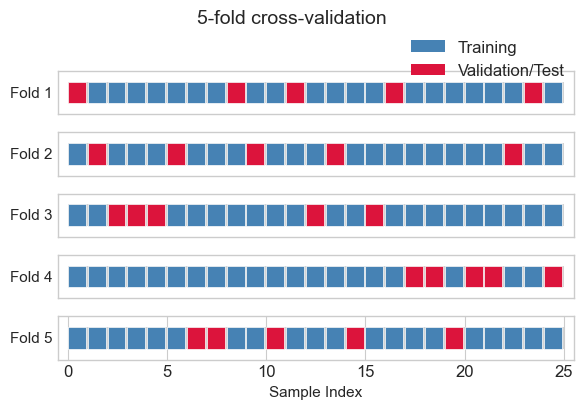

In [164]:
from sklearn.model_selection import cross_val_score, KFold

# Visualise K-Fold splitting
n_samples_cv = 25
n_folds = 5

fig, axes = plt.subplots(n_folds, 1, figsize=(6, 4))

kfold = KFold(n_splits=n_folds, shuffle=True, random_state=42)
indices = np.arange(n_samples_cv)

for fold, (train_idx, test_idx) in enumerate(kfold.split(indices)):
    ax = axes[fold]
    
    # Create color array
    colors = ['steelblue'] * n_samples_cv
    for idx in test_idx:
        colors[idx] = 'crimson'
    
    ax.barh(0, len(indices), left=0, height=0.5, color='lightgray')
    for i, c in enumerate(colors):
        ax.barh(0, 0.9, left=i, height=0.5, color=c, edgecolor='white', linewidth=0.5)
    
    ax.set_xlim(-0.5, n_samples_cv + 0.5)
    ax.set_ylim(-0.5, 0.5)
    ax.set_yticks([])
    ax.set_ylabel(f'Fold {fold + 1}', fontsize=11, rotation=0, ha='right', va='center')
    if fold == n_folds - 1:
        ax.set_xlabel('Sample Index', fontsize=11)
    else:
        ax.set_xticks([])

# Add legend
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='steelblue', label='Training'),
                   Patch(facecolor='crimson', label='Validation/Test')]
fig.legend(handles=legend_elements, loc='upper right', bbox_to_anchor=(0.98, 0.98))

plt.suptitle(f'{n_folds}-fold cross-validation', 
             fontsize=14, y=1.02)
plt.tight_layout()
plt.show()


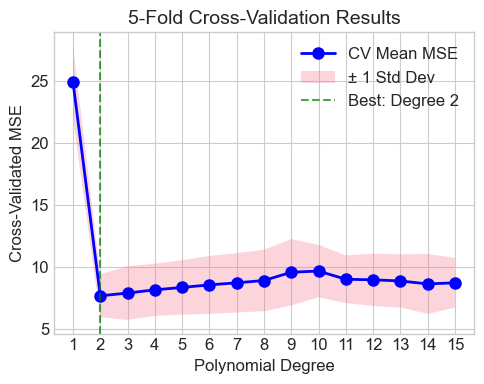

Best model by cross-validation: Degree 2
CV MSE: 7.65 ± 1.73


In [165]:
# Apply cross-validation to compare polynomial models
degrees_to_try = range(1, 16)
cv_means = []
cv_stds = []

for degree in degrees_to_try:
    model = make_pipeline(
        PolynomialFeatures(degree, include_bias=False),
        LinearRegression()
    )
    
    # 5-fold cross-validation, using negative MSE (sklearn convention is to use negative scores)
    scores = cross_val_score(model, X_full, y_full, cv=5, scoring='neg_mean_squared_error')
    mse_scores = -scores  # Convert back to positive MSE
    
    cv_means.append(mse_scores.mean())
    cv_stds.append(mse_scores.std())

cv_means = np.array(cv_means)
cv_stds = np.array(cv_stds)

# Plot
fig, ax = plt.subplots(figsize=(5, 4))

ax.plot(degrees_to_try, cv_means, 'b-o', linewidth=2, markersize=8, label='CV Mean MSE')
ax.fill_between(degrees_to_try, cv_means - cv_stds, cv_means + cv_stds, alpha=0.3, 
                label='± 1 Std Dev')

# Mark the best model
best_degree = list(degrees_to_try)[np.argmin(cv_means)]
ax.axvline(x=best_degree, color='green', linestyle='--', alpha=0.7, 
           label=f'Best: Degree {best_degree}')

ax.set_xlabel('Polynomial Degree', fontsize=12)
ax.set_ylabel('Cross-Validated MSE', fontsize=12)
ax.set_title('5-Fold Cross-Validation Results', fontsize=14)
ax.legend()
ax.set_xticks(degrees_to_try)

plt.tight_layout()
plt.show()

print(f"Best model by cross-validation: Degree {best_degree}")
print(f"CV MSE: {cv_means[best_degree-1]:.2f} ± {cv_stds[best_degree-1]:.2f}")


> ### Your turn 7: cross-validation on real data
>
> `load_diabetes` ships with scikit-learn: 442 patients, 10 features, no download needed.
>
> 1. Run 10-fold cross-validation on a plain `LinearRegression`.
> 2. Report the mean and the standard deviation of the R² scores.
> 3. What does the standard deviation tell you that the mean does not?

In [166]:
from sklearn.datasets import load_diabetes

data = load_diabetes()
X_diab, y_diab = data.data, data.target

# TODO: 10-fold cross_val_score with scoring='r2'
# TODO: print the mean and the standard deviation

---

## Summary

| Concept | What it is | Remember |
|---------|------------|------------------|
| **Loss function** | one number for how wrong the model is | it defines what "good" means, and you chose it |
| **Gradient descent** | step downhill on the loss surface | the learning rate decides whether you arrive |
| **Overfitting** | memorising noise instead of pattern | low training error, high test error |
| **Underfitting** | too simple to capture the pattern | high error on both |
| **Bias-variance** | complexity trades one for the other | the minimum of the sum is the target |
| **Train-test split** | hold data back to estimate generalisation | simple, and noisy |
| **Cross-validation** | every point gets a turn in the test set | steadier, and gives you a spread |

The error you can see is not the error you care about. Everything in Part 2 is a way of
estimating the error you cannot see.

---

## Reflection

Write brief answers:

1. **Why can't we just minimise training error?** What goes wrong if it is your only guide?
2. **If cross-validation is better, why would anyone use a single train-test split?**
3. **Deep learning models have millions of parameters. How do they generalise at all?**
   This is an open research question, and the subject of the 6.2 Extension.

---